In [1]:
import grewpy
from grewpy import Corpus, CorpusDraft, Request
from collections import Counter
import sys
sys.path.insert(1, "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/tod")

import tod.corpus

treebank_path = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie-master/prosody_pauses"
grew_pattern = "pattern{X[upos<>PUNCT]}"
patterns_text_file = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/3. probability_matrix/patterns_all_nodes_prosody.txt"
analysed_category = "all_nodes"


connected to port: 52809


In [2]:
import numpy as np

# ── 1. FEATURE CLASSIFICATION ────────────────────────────────────────────────

# Drop entirely: redundant, unreliable, or too fine-grained
FEATURES_TO_DROP = {
    'MeanF0',           # use SemitonesFromUtteranceMean instead (speaker-normalised)
    'MeanF0Step',       # threshold artefact, not a prosodic observation
    'AvgAmplitude',     # recording-condition-dependent
    'MaxAmplitude',     # same
    'SylForm',          # phonetic transcription, too fine-grained
    'AlignBegin',       # timing offset, not linguistic
    'AlignEnd',         # timing offset, not linguistic
    'pauseID',          # identifier, not a feature
    # Before*/Next* equivalents of dropped features:
    'BeforeMeanF0', 'BeforeMeanF0Step', 'BeforeAvgAmplitude',
    'NextMeanF0',   'NextMeanF0Step',   'NextAvgAmplitude',
    'Semiton', 'Overlap', 'Loc', 'Glo', 'Backchannel'
}

# Bin into 3 quantile-based categories: these are continuous but informative
# Note: Duration appears in TWO units in your data:
#   - syllable subnodes: integer ms  (e.g. 289, 167)
#   - pause nodes:       float seconds (e.g. 0.2695, 0.3328)
# We normalise everything to ms before binning.
FEATURES_TO_BIN = {
    'SemitonesFromUtteranceMean',
    'Duration',   # needs unit normalisation — see _normalise_duration() below
    # Before*/Next* equivalents:
    'BeforeSemitonesFromUtterance',
    'NextSemitonesFromUtterance',
    'BeforeDuration',   # if present
    'NextDuration',     # if present
    'BeforeSemiton',
    'NextSemiton',
    'NextSemitonsFromUtterance'
}

In [3]:
def _normalise_duration(value_str: str) -> float:
    """Convert Duration string to milliseconds regardless of source node type.
    Syllable subnodes store ms (e.g. '289').
    Pause nodes store seconds (e.g. '0.2695').
    Heuristic: values < 10 are in seconds.
    Zero or invalid → return None (missing / sentinel value).
    """
    try:
        v = float(value_str)
    except (ValueError, TypeError):
        return None
    if v == 0.0:
        return None   # sentinel for missing data (e.g. overlap nodes)
    return v * 1000 if v < 10 else v   # seconds → ms if < 10


In [4]:
def _is_sentinel(value_str: str) -> bool:
    """Catch the '0.0' sentinel values that appear on overlap/missing pause nodes.
    example from test file: node 32's pause has all-zero Before*/Next* values because the audio overlaps with another sentence. we want to catch these and drop them silently rather than binning them as F0_low.
    """
    try:
        return float(value_str) == 0.0
    except (ValueError, TypeError):
        return False

In [5]:
def _feature_name(key: tuple) -> str:
    """Extract the bare feature name from a key like ('node','X','child','Duration')."""
    return key[-1]

In [6]:
def collect_continuous_values(all_data_items):
    """
    all_data_items: iterable of (lex_unit, match, features) triples
    where features is the dict returned by grex.data.extract_features().
    
    Returns a dict: {feature_name: [float, float, ...]} with all observed values.
    """
    collector = {f: [] for f in FEATURES_TO_BIN}

    for _, _, features in all_data_items:
        for key, value in features.items():
            fname = _feature_name(key)
            if fname not in FEATURES_TO_BIN:
                continue
            # value can be a plain string (own/parent/prev/next)
            # or a set of strings (child, which can have multiple syllables)
            values = value if isinstance(value, set) else {value}
            for v in values:
                if fname == 'Duration':
                    norm = _normalise_duration(v)
                    if norm is not None:
                        collector['Duration'].append(norm)
                else:
                    if not _is_sentinel(v):
                        try:
                            collector[fname].append(float(v))
                        except (ValueError, TypeError):
                            pass
    return collector

In [7]:
def compute_thresholds(collector: dict, n_bins: int = 3) -> dict:
    """
    Returns a dict: {feature_name: [boundary1, boundary2, ...]}
    with (n_bins - 1) boundaries derived from corpus quantiles.
    """
    thresholds = {}
    for fname, values in collector.items():
        if not values:
            continue
        arr = np.array(values)
        quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]   # interior boundaries only
        thresholds[fname] = np.quantile(arr, quantiles).tolist()
    return thresholds

In [8]:
BIN_LABELS = {
    'SemitonesFromUtteranceMean':    ['F0_low',    'F0_mid',    'F0_high'],
    'Duration':                      ['Dur_short', 'Dur_mid',   'Dur_long'],
    'BeforeSemitonesFromUtterance':  ['BeforeF0_low',  'BeforeF0_mid',  'BeforeF0_high'],
    'NextSemitonesFromUtterance':    ['NextF0_low',    'NextF0_mid',    'NextF0_high'],
}

In [9]:
def _bin_value(fname: str, value_str: str, thresholds: dict) -> str | None:
    """
    Convert a continuous string value to a bin label.
    Returns None if the value should be skipped (sentinel, missing, out-of-range).
    """
    if fname not in thresholds:
        return None
    if _is_sentinel(value_str):
        return None

    if fname == 'Duration':
        v = _normalise_duration(value_str)
    else:
        try:
            v = float(value_str)
        except (ValueError, TypeError):
            return None

    if v is None:
        return None

    bounds = thresholds[fname]
    labels = BIN_LABELS.get(fname, [f'{fname}_Q1', f'{fname}_Q2', f'{fname}_Q3'])
    # find which bin: below first boundary → label[0], etc.
    for i, b in enumerate(bounds):
        if v <= b:
            return labels[i]
    return labels[-1]

In [10]:
def format_features(features: dict, thresholds: dict) -> list[str]:
    """
    Replace the original formatted_features list comprehension.
    
    features:   the dict from grex.data.extract_features()
    thresholds: computed by compute_thresholds() over the full corpus
    
    Returns a list of 'key1:key2:...:keyN=value' strings,
    with continuous features binned and dropped features excluded.
    """
    result = []

    for key, value in features.items():
        fname = _feature_name(key)
        prefix = ':'.join(key)

        # ── DROP ──────────────────────────────────────────────────────────────
        if fname in FEATURES_TO_DROP:
            continue

        # ── BIN (continuous → categorical label) ─────────────────────────────
        if fname in FEATURES_TO_BIN:
            values = value if isinstance(value, set) else {value}
            for v in values:
                label = _bin_value(fname, v, thresholds)
                if label is not None:
                    result.append(f"{prefix}={label}")
            continue

        # ── KEEP AS-IS (already categorical) ─────────────────────────────────
        if isinstance(value, set):
            for v in value:
                result.append(f"{prefix}={v}")
        else:
            result.append(f"{prefix}={value}")

    return result

In [11]:
def _filter_features(features, excluded_patterns=None, included_patterns=None):
    import re
    filtered_features = []
    for feature in features:
        # Check exclusion patterns
        should_exclude = False
        if excluded_patterns:
            for pattern in excluded_patterns:
                if re.search(pattern, feature):  # Use 'pattern', not 'excluded_patterns'
                    should_exclude = True
                    break
        if should_exclude:
            continue
        
        # Check inclusion patterns (only if not excluded)
        should_include = True
        if included_patterns:
            should_include = False
            for pattern in included_patterns:
                if re.search(pattern, feature):  # Use 'pattern', not 'included_patterns'
                    should_include = True
                    break
        if should_include:
            filtered_features.append(feature)
    return filtered_features

In [12]:
import yaml
sys.path.insert(1, "/Users/madalina/Documents/M2TAL/stage/grex/grex2")
import pyximport
import pandas as pd
pyximport.install()
import grex.data
import grex.utils
import grex.features
import grex.data_prosody

grewpy.set_config("sud")
corpus = grewpy.Corpus(treebank_path)
draft = grewpy.CorpusDraft(corpus)
all_matches = corpus.search(
            grewpy.Request(grew_pattern)
            .without("X[InIdiom=Yes]")
            .without("X[Idiom=Yes]")
            .without("X[InTitle=Yes]")
            .without("X[Title=Yes]")
            .without("X[Scrap=Yes]")
            .without("X[Foreign]")
            .without("X[Lang]")
            .without("X-[fixed]->Y")
            .without("Y-[flat:name]->X")
            .without("Y-[goeswith]->X"),
            clustering_parameter=["X.lemma"],
        )
sent_id_to_sentence = {
            draft[i].meta["sent_id"]: draft[i].features for i in range(len(draft)) # type: ignore
        }

matches = {}
for key, value in all_matches.items(): # type: ignore
    # remove those that have less than 10 occurrences
    if len(value) > 10:
        matches[key] = value

match_upos = {}
        # iterating through each lemma and its values like this: '€': [{'sent_id': 'fr-ud-train_11309', 'matching': {'nodes': {'X': '7'}, 'edges': {}}}]
for key, value in matches.items():
    # iterating through each match for the lemma so for example {'sent_id': 'fr-ud-train_11309', 'matching': {'nodes': {'X': '7'}, 'edges': {}}}
    for m in value:
        match_sent_id = m["sent_id"]
        match_node_index = str(m["matching"]["nodes"]["X"])
        if match_sent_id in sent_id_to_sentence:
            current_sentence_features = sent_id_to_sentence[match_sent_id]
            if match_node_index in current_sentence_features.keys():
                current_token_features = current_sentence_features[
                    match_node_index
                ]
                # if the token has a feature called ExtPos, we use that as the key, otherwise we use the upos feature
                # ExtPos is used for example in 10% -> % has upos SYM but ExtPos Noun , so we want to use noun
                # and what we're doing is creating a dictionary with keys (lemma, pos) and values as a list of matches
                # so for example ('reason', 'NOUN') -> [match1, match2, match3] where a match looks like this: {'sent_id': 'fr-ud-train_11309', 'matching': {'nodes': {'X': '7'}, 'edges': {}}}
                
                if "ExtPos" in current_token_features:
                    match_upos.setdefault(
                        (key, current_token_features["ExtPos"]), []
                    ).append(m)
                else:
                    try:
                        match_upos.setdefault(
                            (key, current_token_features["upos"]), []
                        ).append(m)
                    except KeyError:
                        print(f"WARNING: Token with lemma '{key}' in sentence '{match_sent_id}' does not have a 'upos' feature.")

new_match_upos = {}
for key, value in match_upos.items():
    if len(value) > 10:
        new_match_upos[key] = value
match_upos = new_match_upos

for key, value in match_upos.items():
    if len(value) < 10:
        print(f"WARNING: {key} has only {len(value)} occurrences but passed filtering!")
with open(patterns_text_file) as in_stream:
            config = yaml.load(in_stream, Loader=yaml.Loader)

templates = grex.utils.FeaturePredicate.from_config(config["templates"])
feature_predicate = grex.utils.FeaturePredicate.from_config(
    config["features"], templates=templates
)

all_data_items = []
for lex_unit, mts in match_upos.items():
    for match in mts:
        features = grex.data_prosody.extract_features(draft, match, feature_predicate)
        all_data_items.append((lex_unit, match, features))

collector  = collect_continuous_values(all_data_items)
thresholds = compute_thresholds(collector, n_bins=3)

print("Computed thresholds:")
for fname, bounds in thresholds.items():
    labels = BIN_LABELS.get(fname, ['Q1','Q2','Q3'])
    print(f"  {fname}: <{bounds[0]:.3f} → {labels[0]} | "
          f"<{bounds[1]:.3f} → {labels[1]} | ≥{bounds[1]:.3f} → {labels[2]}")

# --- SECOND PASS: format with binning applied ---
data = {k: list() for k in match_upos}

for lex_unit, match, features in all_data_items:
    formatted = format_features(features, thresholds)
    # if excluded_feature_patterns or included_feature_patterns:
    formatted = _filter_features(
        formatted,
        excluded_patterns=['own'],
        # included_patterns=included_feature_patterns
    )
    data[lex_unit].append(formatted)

unique_lemma = sorted(set([k for k in data]))
unique_features = sorted(set(
    feat
    for _, match_upos in data.items()
    for m in match_upos
    for feat in m
))

idx2feature = {i: feat for i, feat in enumerate(unique_features)}
feature2idx = {feat: i for i, feat in idx2feature.items()}
idx2lexunit = {i: feat for i, feat in enumerate(unique_lemma)}
lexunit2idx = {feat: i for i, feat in idx2lexunit.items()}

Computed thresholds:
  SemitonesFromUtteranceMean: <-1.243 → F0_low | <0.517 → F0_mid | ≥0.517 → F0_high
  Duration: <129.000 → Dur_short | <189.000 → Dur_mid | ≥189.000 → Dur_long


In [13]:
data

{('être',
  'AUX'): [['node:X:parent:position=before',
   'node:X:parent:upos=NOUN',
   'node:X:childSyl1:AvgHeightGlo=M',
   'node:X:childSyl1:AvgHeightLoc=M',
   'node:X:childSyl1:Duration=Dur_mid',
   'node:X:childSyl1:PitchRangeGlo=M',
   'node:X:childSyl1:PitchRangeLoc=M',
   'node:X:childSyl1:SemitonesFromUtteranceMean=F0_mid',
   'node:X:childSyl1:Slope=Rise',
   'node:X:childSyl1:SlopeGlo=Fall',
   'node:X:childSyl1:SlopeLoc=Fall',
   'node:X:prevSyl:AvgHeightGlo=M',
   'node:X:prevSyl:AvgHeightLoc=M',
   'node:X:prevSyl:Duration=Dur_short',
   'node:X:prevSyl:PitchRangeGlo=L',
   'node:X:prevSyl:PitchRangeLoc=L',
   'node:X:prevSyl:SemitonesFromUtteranceMean=F0_high',
   'node:X:prevSyl:Slope=Flat',
   'node:X:prevSyl:SlopeGlo=Flat',
   'node:X:prevSyl:SlopeLoc=Flat',
   'node:X:nextSyl:AvgHeightGlo=M',
   'node:X:nextSyl:AvgHeightLoc=M',
   'node:X:nextSyl:Duration=Dur_short',
   'node:X:nextSyl:PitchRangeGlo=L',
   'node:X:nextSyl:PitchRangeLoc=L',
   'node:X:nextSyl:Semiton

In [14]:
co_occurrence_matrix = np.zeros((len(idx2lexunit), len(idx2feature)))
for lexunit, feature_lists in data.items():
    for feature_list in feature_lists:
        for feature in feature_list:
            co_occurrence_matrix[lexunit2idx[lexunit], feature2idx[feature]] += 1

coverage_matrix = np.zeros((len(idx2lexunit), len(idx2feature)))
row_sums = co_occurrence_matrix.sum(axis=1)
coverage_matrix = co_occurrence_matrix / row_sums[:, np.newaxis]
# Avoid division by zero
coverage_matrix[np.isnan(coverage_matrix)] = 0
feature_matrix = coverage_matrix

In [36]:
import numpy as np
import pandas as pd
from scipy.stats import entropy
from collections import Counter
from sklearn.metrics.pairwise import cosine_similarity

syntactic_mask = np.array([
    not any(p in feat for p in ['childSyl', 'prevSyl', 'nextSyl', 
                                  'Slope', 'Glo', 'Loc', 'Duration', 
                                  'PitchRange', 'AvgHeight', 'Semiton',
                                  'F0', 'Fused'])
    for feat in idx2feature.values()
])
prosodic_mask = ~syntactic_mask

similarity_syntactic = cosine_similarity(feature_matrix[:, syntactic_mask])
similarity_prosodic  = cosine_similarity(feature_matrix[:, prosodic_mask])

similarity_matrix = cosine_similarity(feature_matrix)
# 1. PRE-CALCULATION: Global Category Frequencies (Freq(c))
# This must be done outside the loop to use in the P_norm formula
all_tags = [lu[1] for lu in idx2lexunit.values()]
total_count = len(all_tags)
category_freqs = {cat: count / total_count for cat, count in Counter(all_tags).items()}

scores = {}

for idx, lex_unit in idx2lexunit.items():
    current_category = lex_unit[1]
    
    # 2. NEIGHBORHOOD SEARCH: Apply 0.7 threshold AND max 20 constraint
    # Find all neighbors with similarity >= 0.7
    threshold_mask = similarity_syntactic[idx] >= 0.7
    potential_indices = np.where(threshold_mask)[0]
    
    # Filter out the word itself and sort by similarity (descending)
    valid_neighbours = sorted(
        [i for i in potential_indices if i != idx],
        key=lambda x: similarity_syntactic[idx][x],
        reverse=True
    )[:20] # This is your neighborhood cap k=20
    
    if not valid_neighbours:
        continue # Skip words with no strong distributional alignments

    # 3. CALCULATE RAW WEIGHTS (w_i)
    category_weights = {}
    purity_bottom = 0 # This is the sum of similarity weights
    
    for neighbour_idx in valid_neighbours:
        neighbour_category = idx2lexunit[neighbour_idx][1]
        w_i = similarity_syntactic[idx][neighbour_idx]
        purity_bottom += w_i
        category_weights[neighbour_category] = category_weights.get(neighbour_category, 0) + w_i

    # 4. CALCULATE P_norm(c)
    # First, calculate raw P(c) and divide by global frequency
    norm_weights = {}
    for cat, weight in category_weights.items():
        raw_p_c = weight / purity_bottom
        norm_weights[cat] = raw_p_c / category_freqs[cat]
    
    # Re-normalize so the distribution sums to 1 (the denominator in your P_norm formula)
    total_norm_sum = sum(norm_weights.values())
    p_norm = {cat: val / total_norm_sum for cat, val in norm_weights.items()}

    # 5. PURITY AND ENTROPY (Using p_norm)
    # Purity is the mass assigned to the word's own annotated tag
    purity_score = p_norm.get(current_category, 0)
    
    # Entropy calculated on the normalized distribution
    entropy_score = entropy(list(p_norm.values()))
    
    # 6. IDENTIFY RIVAL (For your Bridge Word analysis)
    rival_cat = None
    rival_p = 0
    for cat, p in p_norm.items():
        if cat != current_category and p > rival_p:
            rival_p = p
            rival_cat = cat

    scores[lex_unit] = {
        "purity": purity_score,
        "entropy": entropy_score,
        "rival_category": rival_cat,
        "rival_weight_ratio": rival_p
    }

In [37]:
all_data_full = []
all_data_intruders = []

for idx, lex_unit in idx2lexunit.items():
    current_cat = lex_unit[1]
    
    threshold_indices = np.where(similarity_syntactic[idx] > 0.7)[0]
    closest_neighbours = sorted(
        [n_idx for n_idx in threshold_indices if n_idx != idx],
        key=lambda x: similarity_syntactic[idx][x], reverse=True
    )[:20]

    if not closest_neighbours: continue

    # 1. Calculate weighted categorical counts for this neighborhood
    raw_weights = {}
    total_raw_weight = 0
    for n_idx in closest_neighbours:
        n_cat = idx2lexunit[n_idx][1]
        sim = similarity_syntactic[idx][n_idx]
        raw_weights[n_cat] = raw_weights.get(n_cat, 0) + sim
        total_raw_weight += sim

    # 2. Normalize by Global Category Frequency (P_norm)
    norm_probs = {}
    for cat, weight in raw_weights.items():
        # Divide relative weight by global frequency
        norm_probs[cat] = (weight / total_raw_weight) / category_freqs[cat]
    
    # Re-normalize to sum to 1
    sum_norm = sum(norm_probs.values())
    for cat in norm_probs:
        norm_probs[cat] /= sum_norm
        
        # # Data for FULL matrix (Stability)
        all_data_full.append({"Original": current_cat, "Neighbor": cat, "Weight": norm_probs[cat]})
        
        # Data for INTRUDER matrix (Zoom)
        # if cat != current_cat:
            # all_data_intruders.append({"Original": current_cat, "Neighbor": cat, "Weight": norm_probs[cat]})


# 2. Build the Transition (Overlap) Matrix
df = pd.DataFrame(all_data_full)
# df = pd.DataFrame(all_data_intruders)
# Sum all normalized weights for each (Original, Neighbor) pair
# This gives the "Stability" on the diagonal and "Overlap" off-diagonal
matrix = df.groupby(['Original', 'Neighbor'])['Weight'].sum().unstack(fill_value=0)

# Final Normalization: make each ROW sum to 1.0
# This gives the probability: "Given category X, what is the distribution of its neighbors?"
transition_matrix = matrix.div(matrix.sum(axis=1), axis=0)
# transition_matrix = transition_matrix.drop(index="X")
# transition_matrix = transition_matrix.drop(columns="X")
# transition_matrix = transition_matrix.drop(index="SYM")
# transition_matrix = transition_matrix.drop(columns="SYM")

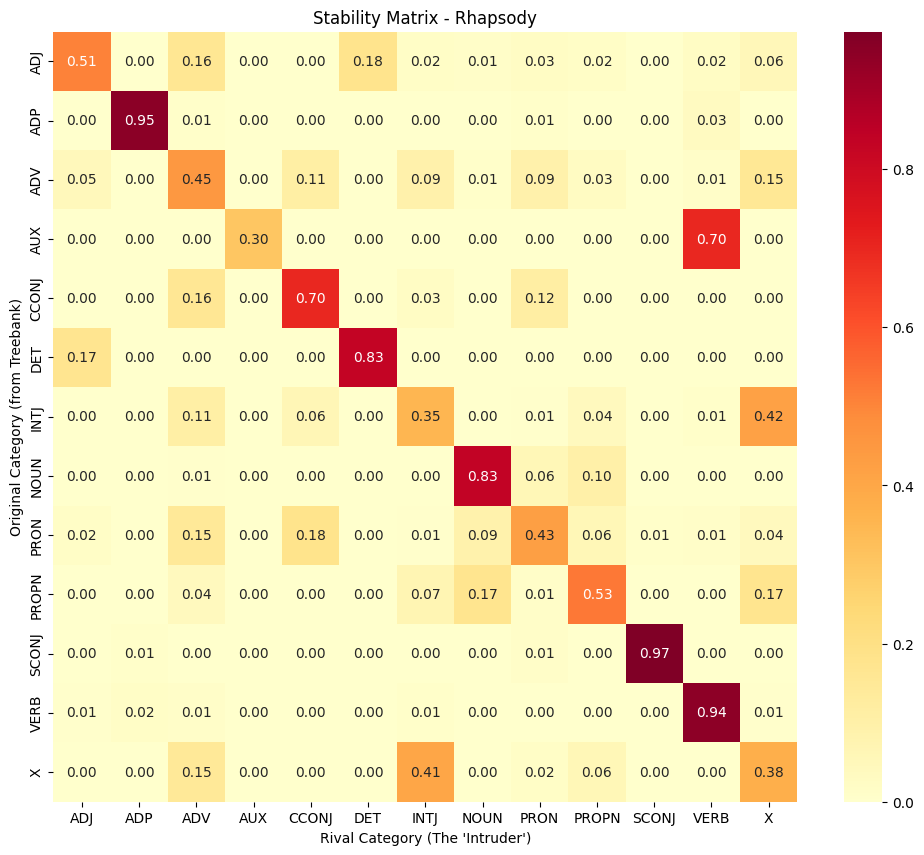

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 10))
sns.heatmap(
    transition_matrix, 
    annot=True,      # Show the numbers in the cells
    cmap="YlOrRd",   # Color gradient: Yellow (low) to Red (high)
    fmt=".2f"        # Format to 2 decimal places
)

plt.title("Stability Matrix - Rhapsody")
plt.ylabel("Original Category (from Treebank)")
plt.xlabel("Rival Category (The 'Intruder')")
plt.show()

In [39]:
transition_matrix

Neighbor,ADJ,ADP,ADV,AUX,CCONJ,DET,INTJ,NOUN,PRON,PROPN,SCONJ,VERB,X
Original,,,,,,,,,,,,,
ADJ,0.509608,0.000000,0.162034,0.000000,0.000000,0.177987,0.018737,0.011937,0.025548,0.015418,0.000000,0.022923,0.055809
ADP,0.000000,0.948836,0.008500,0.000000,0.000000,0.000000,0.000000,0.001378,0.009428,0.000000,0.000000,0.031858,0.000000
ADV,0.046685,0.000000,0.451790,0.000000,0.111697,0.000000,0.093769,0.009188,0.092159,0.028065,0.000000,0.011871,0.154776
AUX,0.000000,0.000000,0.000000,0.302717,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.697283,0.000000
CCONJ,0.000000,0.000000,0.158293,0.000000,0.699116,0.000000,0.025858,0.000000,0.116734,0.000000,0.000000,0.000000,0.000000
DET,0.170627,0.000000,0.000000,0.000000,0.000000,0.829373,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
INTJ,0.002051,0.000000,0.107080,0.000000,0.063384,0.000000,0.351101,0.000000,0.007166,0.039042,0.000000,0.008106,0.422069
NOUN,0.003377,0.000994,0.005020,0.000000,0.000000,0.000000,0.000000,0.833087,0.057336,0.099846,0.000000,0.000340,0.000000
PRON,0.018393,0.003681,0.146338,0.000000,0.181789,0.000000,0.006254,0.088092,0.429686,0.060326,0.010398,0.014591,0.040452


In [18]:
all_data_full = []
all_data_intruders = []

for idx, lex_unit in idx2lexunit.items():
    current_cat = lex_unit[1]
    
    threshold_indices = np.where(similarity_matrix[idx] > 0.7)[0]
    closest_neighbours = sorted(
        [n_idx for n_idx in threshold_indices if n_idx != idx],
        key=lambda x: similarity_matrix[idx][x], reverse=True
    )[:20]

    if not closest_neighbours: continue

    # 1. Calculate weighted categorical counts for this neighborhood
    raw_weights = {}
    total_raw_weight = 0
    for n_idx in closest_neighbours:
        n_cat = idx2lexunit[n_idx][1]
        sim = similarity_matrix[idx][n_idx]
        raw_weights[n_cat] = raw_weights.get(n_cat, 0) + sim
        total_raw_weight += sim

    # 2. Normalize by Global Category Frequency (P_norm)
    norm_probs = {}
    for cat, weight in raw_weights.items():
        # Divide relative weight by global frequency
        norm_probs[cat] = (weight / total_raw_weight) / category_freqs[cat]
    
    # Re-normalize to sum to 1
    sum_norm = sum(norm_probs.values())
    for cat in norm_probs:
        norm_probs[cat] /= sum_norm
        
        # # Data for FULL matrix (Stability)
        all_data_full.append({"Original": current_cat, "Neighbor": cat, "Weight": norm_probs[cat]})
        
        # Data for INTRUDER matrix (Zoom)
        # if cat != current_cat:
        #     all_data_intruders.append({"Original": current_cat, "Neighbor": cat, "Weight": norm_probs[cat]})


# 2. Build the Transition (Overlap) Matrix
df = pd.DataFrame(all_data_full)
# df = pd.DataFrame(all_data_intruders)
# Sum all normalized weights for each (Original, Neighbor) pair
# This gives the "Stability" on the diagonal and "Overlap" off-diagonal
matrix = df.groupby(['Original', 'Neighbor'])['Weight'].sum().unstack(fill_value=0)

# Final Normalization: make each ROW sum to 1.0
# This gives the probability: "Given category X, what is the distribution of its neighbors?"
transition_matrix = matrix.div(matrix.sum(axis=1), axis=0)
# transition_matrix = transition_matrix.drop(index="X")
# transition_matrix = transition_matrix.drop(columns="X")
# transition_matrix = transition_matrix.drop(index="SYM")
# transition_matrix = transition_matrix.drop(columns="SYM")

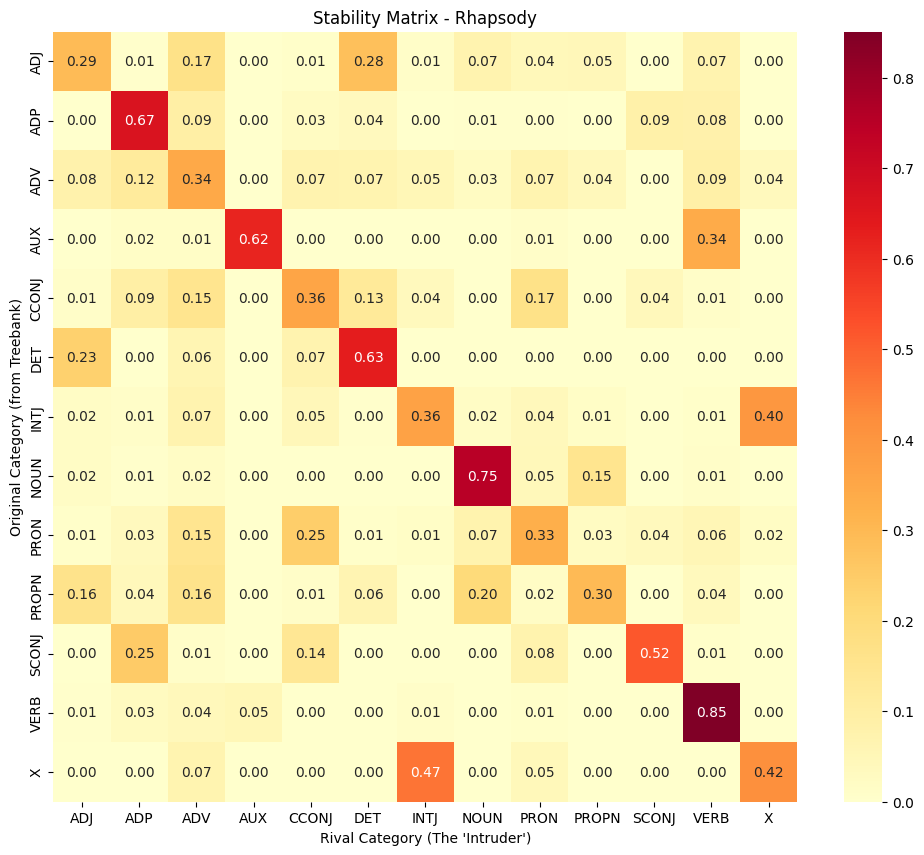

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12, 10))
sns.heatmap(
    transition_matrix, 
    annot=True,      # Show the numbers in the cells
    cmap="YlOrRd",   # Color gradient: Yellow (low) to Red (high)
    fmt=".2f"        # Format to 2 decimal places
)

plt.title("Stability Matrix - Rhapsody")
plt.ylabel("Original Category (from Treebank)")
plt.xlabel("Rival Category (The 'Intruder')")
plt.show()

In [31]:
transition_matrix

Neighbor,ADJ,ADP,ADV,AUX,CCONJ,DET,INTJ,NOUN,PRON,PROPN,SCONJ,VERB,X
Original,,,,,,,,,,,,,
ADJ,0.294669,0.006344,0.166415,0.000000,0.007152,0.280676,0.010636,0.070629,0.043405,0.046980,0.000000,0.073093,0.000000
ADP,0.002240,0.666765,0.093800,0.000000,0.025833,0.035601,0.000000,0.005096,0.004489,0.000000,0.085818,0.080359,0.000000
ADV,0.076987,0.116991,0.343548,0.000000,0.072696,0.069471,0.051852,0.025800,0.068688,0.039934,0.002990,0.092126,0.038915
AUX,0.000000,0.015182,0.014699,0.617209,0.000000,0.000000,0.000000,0.000000,0.012126,0.000000,0.000000,0.340785,0.000000
CCONJ,0.012840,0.094228,0.151187,0.000000,0.357475,0.125023,0.039036,0.000000,0.167306,0.000000,0.042153,0.010752,0.000000
DET,0.234116,0.000000,0.061215,0.000000,0.071334,0.633336,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
INTJ,0.019479,0.010430,0.071352,0.000000,0.049393,0.004829,0.363717,0.019266,0.042751,0.013424,0.000000,0.009840,0.395519
NOUN,0.017141,0.006171,0.017702,0.000000,0.000000,0.000000,0.000000,0.749221,0.046130,0.150970,0.000000,0.012665,0.000000
PRON,0.009405,0.034193,0.146405,0.000000,0.245297,0.008977,0.014272,0.074769,0.325805,0.025281,0.037378,0.055492,0.022727


In [20]:
def get_top_bridge_words(scores_dict, original_cat, rival_cat, top_n=100):
    """Finds the words from original_cat most pulled toward rival_cat."""
    matches = []

    for (word, o_cat), data in scores_dict.items():
        if o_cat == original_cat and data["rival_category"] == rival_cat:
            matches.append({
                "word": word,
                "purity": float(data["purity"]),
                "entropy": float(data["entropy"]),
            })

    matches.sort(
        key=lambda x: (0.7 * x["purity"] - 0.3 * x["entropy"]),
        reverse=False
    )

    return [(m["word"], f'{m["purity"]:.2f}', f'{m["entropy"]:.2f}') for m in matches[:top_n]]

# Example: Who are the Verbs that look like Adjectives?
category_to_compare_1 = "NOUN"
category_to_compare_2 = "PROPN"
bridge_verbs = get_top_bridge_words(scores, category_to_compare_1, category_to_compare_2)
print(f"Top {category_to_compare_1} -> {category_to_compare_2} bridge words: ")
print(f"Word \t Purity \t Entropy")
for v in bridge_verbs:
    print(v)

Top NOUN -> PROPN bridge words: 
Word 	 Purity 	 Entropy
('vue', '0.16', '1.82')
('exemple', '0.26', '1.56')
('abord', '0.30', '1.52')
('tout', '0.30', '1.18')
('an', '0.43', '1.43')
('tram', '0.48', '1.36')
('gauche', '0.53', '1.19')
('ligne', '0.49', '0.93')
('gens', '0.55', '1.00')
('art', '0.55', '1.00')
('homme', '0.55', '1.00')
('guerre', '0.55', '1.00')
('soir', '0.56', '0.99')
('part', '0.60', '0.94')
('femme', '0.62', '0.89')
('poste', '0.63', '0.90')
('ville', '0.63', '0.89')
('gare', '0.63', '0.89')
('pied', '0.63', '0.89')
('fond', '0.63', '0.89')
('droite', '0.63', '0.89')
('livre', '0.63', '0.89')
('monde', '0.63', '0.89')
('place', '0.55', '0.69')
('temps', '0.63', '0.89')
('siècle', '0.63', '0.88')
('fin', '0.55', '0.69')
('cas', '0.64', '0.88')
('droit', '0.64', '0.88')
('jour', '0.64', '0.88')
('grippe', '0.56', '0.69')
('heure', '0.66', '0.82')
('musique', '0.71', '0.60')
('début', '0.72', '0.59')
('sorte', '0.72', '0.59')
('fois', '0.72', '0.59')
('mal', '0.72', '0.

In [21]:
def get_pulling_features(
    lex_unit,
    rival_category,
    feature_matrix,
    similarity_matrix,
    idx2lexunit,
    lexunit2idx,
    idx2feature,
    feature2idx,
    top_k_features=20
):
    """
    For a given lexical unit, find the features that explain why it is
    pulled toward rival_category in distributional space.

    Ranking logic:
        A feature is "pulling" if:
          (a) the lex_unit has a HIGH value for it (it actually uses the feature), AND
          (b) the difference between the lex_unit and the rival centroid is SMALL
              (the feature is shared with the rival).

        We weight (a) and (b) together as:
            score = unit_value / (difference + epsilon)
        
        Features where the unit has zero value are excluded — they cannot
        be pulling anything.

    Returns a list of dicts sorted by descending score.
    """
    unit_idx = lexunit2idx[lex_unit]           # fix: was undefined `idx`
    unit_vector = feature_matrix[unit_idx]

    # ── 1. Find neighbours above threshold, capped at 20 ──────────────────
    threshold_mask = similarity_matrix[unit_idx] >= 0.7
    neighbour_indices = sorted(
        [i for i in np.where(threshold_mask)[0] if i != unit_idx],
        key=lambda x: similarity_matrix[unit_idx][x],
        reverse=True
    )[:20]

    # ── 2. Rival centroid: median over rival-category neighbours ───────────
    rival_neighbour_indices = [
        i for i in neighbour_indices
        if idx2lexunit[i][1] == rival_category
    ]

    if not rival_neighbour_indices:
        print(f"No neighbours of category '{rival_category}' found for {lex_unit}.")
        return []

    rival_centroid = np.median(
        feature_matrix[rival_neighbour_indices], axis=0
    )

    # ── 3. Feature differences ─────────────────────────────────────────────
    feature_differences = np.abs(unit_vector - rival_centroid)

    # ── 4. Score: high unit value + small difference from rival ────────────
    # Only score features where the unit actually has a non-zero value —
    # a zero-value feature cannot be "pulling" the unit anywhere.
    epsilon = 1e-6
    scores = np.where(
        unit_vector > 0,
        unit_vector / (feature_differences + epsilon),
        0.0
    )

    top_feature_indices = np.argsort(scores)[::-1][:top_k_features]

    # ── 5. Build result table ──────────────────────────────────────────────
    results = []
    for f_idx in top_feature_indices:
        if scores[f_idx] == 0:
            continue
        results.append({
            "feature":     idx2feature[f_idx],
            "unit_value":  unit_vector[f_idx],
            "rival_avg":   rival_centroid[f_idx],
            "diff":        feature_differences[f_idx],
            "score":       scores[f_idx],
        })

    return results


# ── Usage ──────────────────────────────────────────────────────────────────────

results = get_pulling_features(
    ('français', 'ADJ'), "ADV",
    feature_matrix, similarity_matrix,
    idx2lexunit, lexunit2idx,
    idx2feature, feature2idx,
    top_k_features=20
)

print("Top features pulling 'français' (ADJ) toward ADV:")
print(f"{'Feature':<55} {'unit':>6}  {'rival':>6}  {'diff':>6}  {'score':>8}")
print("-" * 90)
for r in results:
    print(
        f"{r['feature']:<55} "
        f"{r['unit_value']:>6.3f}  "
        f"{r['rival_avg']:>6.3f}  "
        f"{r['diff']:>6.3f}  "
        f"{r['score']:>8.2f}"
    )

Top features pulling 'français' (ADJ) toward ADV:
Feature                                                   unit   rival    diff     score
------------------------------------------------------------------------------------------
node:X:childSyl1:AvgHeightLoc=M                          0.018   0.018   0.000    160.18
node:X:nextSyl:SlopeLoc=Flat                             0.008   0.008   0.000     78.26
node:X:parent:upos=VERB                                  0.013   0.013   0.000     50.60
node:X:childSyl1:SlopeGlo=Flat                           0.015   0.014   0.000     36.65
node:X:childSyl1:SlopeLoc=Flat                           0.015   0.014   0.000     36.65
node:X:childSyl1:Slope=Flat                              0.013   0.013   0.000     33.10
node:X:childSyl1:SlopeLoc=Rise                           0.007   0.006   0.000     25.84
node:X:childSyl1:SlopeGlo=Rise                           0.007   0.006   0.000     25.84
node:X:childSyl2:Slope=Rise                              0

In [30]:
def get_aggregate_pulling_features(
    scores_dict,
    original_cat,
    rival_cat,
    feature_matrix,
    similarity_matrix,
    idx2lexunit,
    lexunit2idx,
    idx2feature,
    feature2idx,
    top_k_words=10,
    top_k_features=20,
    similarity_threshold=0.7,
    n_neighbors=20,
):
    """
    Gets the top k bridge words and computes aggregate pulling features across them.

    A feature appears in the aggregate if it was returned by get_pulling_features
    for at least one bridge word. Features are ranked by how consistently and
    strongly they appear across all bridge words (avg_unit_value), with
    count_words as a tiebreaker for robustness.

    Returns a DataFrame sorted by avg_unit_value descending.
    """

    # ── 1. Get top-k bridge words ──────────────────────────────────────────
    bridge_words = get_top_bridge_words(
        scores_dict, original_cat, rival_cat, top_n=top_k_words
    )

    if not bridge_words:
        print(f"No bridge words found from {original_cat} to {rival_cat}")
        return None

    print(f"Analyzing {len(bridge_words)} bridge words: {[w[0] for w in bridge_words]}\n")

    # ── 2. Collect pulling features for each bridge word ──────────────────
    # feature_name -> {"unit_values": [], "rival_avgs": [], "diffs": []}
    all_features_data = {}

    for word, purity_str, entropy_str in bridge_words:
        lex_unit = (word, original_cat)

        if lex_unit not in lexunit2idx:
            print(f"  WARNING: {lex_unit} not found in lexunit2idx, skipping.")
            continue

        word_features = get_pulling_features(
            lex_unit=lex_unit,
            rival_category=rival_cat,
            feature_matrix=feature_matrix,
            similarity_matrix=similarity_matrix,
            idx2lexunit=idx2lexunit,
            lexunit2idx=lexunit2idx,
            idx2feature=idx2feature,
            feature2idx=feature2idx,
            top_k_features=top_k_features * 2,  # cast wide before aggregating
        )

        if not word_features:
            continue

        for feature_dict in word_features:
            feat_name = feature_dict["feature"]
            if feat_name not in all_features_data:
                all_features_data[feat_name] = {
                    "unit_values": [],
                    "rival_avgs":  [],
                    "diffs":       [],
                }
            all_features_data[feat_name]["unit_values"].append(feature_dict["unit_value"])
            all_features_data[feat_name]["rival_avgs"].append(feature_dict["rival_avg"])
            all_features_data[feat_name]["diffs"].append(feature_dict["diff"])

    if not all_features_data:
        print("No features collected — check bridge words and similarity threshold.")
        return None

    # ── 3. Aggregate across words ──────────────────────────────────────────
    aggregate_results = []

    for feature_name, data in all_features_data.items():
        unit_vals  = data["unit_values"]
        rival_vals = data["rival_avgs"]
        diffs      = data["diffs"]

        aggregate_results.append({
            "feature":          feature_name,
            "count_words":      len(unit_vals),          # robustness indicator
            "avg_unit_value":   float(np.mean(unit_vals)),
            "avg_rival_value":  float(np.mean(rival_vals)),
            "avg_diff":         float(np.mean(diffs)),   # small = very shared
            "std_unit_value":   float(np.std(unit_vals)),
        })

    # ── 4. Sort: features shared by most words first, then by avg value ───
    aggregate_results.sort(
        key=lambda x: (x["count_words"], x["avg_unit_value"]),
        reverse=True
    )

    df = pd.DataFrame(aggregate_results[:top_k_features])
    return df


# ── Usage ──────────────────────────────────────────────────────────────────────

df_agg = get_aggregate_pulling_features(
    scores_dict=scores,
    original_cat="CCONJ",
    rival_cat="NOUN",
    feature_matrix=feature_matrix,
    similarity_matrix=similarity_matrix,
    idx2lexunit=idx2lexunit,
    lexunit2idx=lexunit2idx,
    idx2feature=idx2feature,
    feature2idx=feature2idx,
    top_k_words=5,
    top_k_features=20,
)

if df_agg is not None:
    print(df_agg.to_string(index=False))

No bridge words found from CCONJ to NOUN


In [40]:
def calculate_weighted_stability(transition_matrix, category_counts):
    """
    Calculates the Weighted Average Stability of a language.
    
    Args:
        transition_matrix (pd.DataFrame): The full overlap matrix (rows sum to 1).
        category_counts (dict/Series): The frequency of each category (e.g., token counts).
    
    Returns:
        float: The WAS score (0.0 to 1.0).
    """
    # 1. Get the diagonal (Stability of each category)
    # np.diag extracts the diagonal; we match it with index to ensure alignment
    categories = transition_matrix.index
    stability_scores = pd.Series(np.diag(transition_matrix), index=categories)
    
    # 2. Align the counts with the categories present in the matrix
    weights = pd.Series(category_counts).reindex(categories).fillna(0)
    
    # 3. Calculate Weighted Average
    total_weight = weights.sum()
    if total_weight == 0: return 0
    
    weighted_stability = (stability_scores * weights).sum() / total_weight
    
    return weighted_stability

# --- Usage ---
# Use all_data_full to build the matrix
df_full = pd.DataFrame(all_data_full)
# 1. Get the list of all unique categories present in the data (both as source and neighbor)
all_categories = sorted(list(set(df_full['Original']).union(set(df_full['Neighbor']))))

# 2. Build the matrix
matrix_full = df_full.groupby(['Original', 'Neighbor'])['Weight'].sum().unstack(fill_value=0)

# 3. FORCE the matrix to be square
# This adds the missing columns/rows filled with 0s
matrix_full = matrix_full.reindex(index=all_categories, columns=all_categories, fill_value=0)

# 4. Final Normalization (Rows sum to 1.0)
# We add a small epsilon or check for zero-sum rows to avoid division by zero
row_sums = matrix_full.sum(axis=1)
full_transition_matrix = matrix_full.div(row_sums.replace(0, 1), axis=0)

# Calculate the score
was_score = calculate_weighted_stability(full_transition_matrix, category_freqs)
print(f"Global Weighted Stability for this language: {was_score:.4f}")

Global Weighted Stability for this language: 0.7145
